# 05 — Traditional Machine Learning Baselines (FD001)

**Project:** Predictive Intelligence · **Phase 5**

## Objective

Train the first real RUL models and establish the numbers that every later model has to beat. Three model families are compared, from simplest to most flexible:

1. **Linear Regression** — a weighted sum of the features.
2. **Random Forest** — the average of many independent decision trees.
3. **XGBoost** — decision trees built one after another, each correcting the previous ones.

A *baseline* matters because a deep network that cannot beat a well-built simple model is not worth its cost. We do not assume the more complex model wins.

**Protocol.**

1. All choices are made by 5-fold cross-validation on whole training engines.
2. Only then is each model trained on all 100 training engines and scored **once** on the test set.
3. Nothing is changed after seeing the test results.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft. A prediction here is an estimate on benchmark data, not a maintenance instruction.

## 1. Setup and data preparation

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src import config
from src.data.cmapss import add_training_rul, load_subset
from src.data.splits import engine_folds
from src.evaluation.metrics import mae, nasa_score, rmse
from src.features.build import build_tabular_features, cap_rul
from src.visualization import theme

theme.apply_theme()

train, test, test_rul = load_subset("FD001")
train_table, feature_columns = build_tabular_features(
    add_training_rul(train), config.FD001_SENSORS, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
train_table["target"] = cap_rul(train_table["rul"], config.RUL_CAP)

test_table, _ = build_tabular_features(test, config.FD001_SENSORS, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
# A test engine is scored at its last recorded cycle.
test_last_rows = test_table.groupby("engine_id").tail(1).merge(test_rul, on="engine_id")

print(f"Training rows: {len(train_table):,}   features: {len(feature_columns)}   RUL cap: {config.RUL_CAP}")
print(f"Test engines to score: {len(test_last_rows)}")

Training rows: 20,631   features: 56   RUL cap: 125
Test engines to score: 100


## 2. How the models are judged

Throughout, **error = predicted RUL − true RUL**. A negative error means the model called the failure too early (cautious). A positive error means it called it too late, which is the dangerous direction: the engine fails before the model expected.

| Metric | What it tells us | Use it when | Watch out for |
|---|---|---|---|
| **RMSE** | Typical miss in cycles, with big misses counted extra (errors are squared) | Large errors are much worse than small ones | One bad engine can move it a lot |
| **MAE** | The average miss in cycles, plain and simple | You want an easily explained "typically off by N cycles" | Treats a 40-cycle miss as just twice a 20-cycle miss |
| **NASA score** | A penalty that grows exponentially with the miss and punishes late predictions more than early ones | Safety matters and late is worse than early | It is a *sum* over engines, dominated by the worst few, and only comparable on the same set of engines |

Lower is better for all three.

A small example of the asymmetry in the NASA score, for one engine:

In [2]:
pd.DataFrame({
    "error (cycles)": [-20, -10, 0, 10, 20],
    "meaning": ["20 early", "10 early", "exact", "10 late", "20 late"],
    "NASA score": [nasa_score([0], [e]) for e in [-20, -10, 0, 10, 20]],
}).round(2)

,error (cycles),meaning,NASA score
0,-20,20 early,3.66
1,-10,10 early,1.16
2,0,exact,0.00
3,10,10 late,1.72
4,20,20 late,6.39


A 20-cycle late prediction costs about 1.7 times as much as a 20-cycle early one.

**Note on the constants.** The score uses 13 for early and 10 for late predictions, the form used throughout the RUL literature and consistent with the NASA paper's description. The paper's printed constants have not been checked by eye against its equation in this project; see `docs/PROGRESS.md`.

### A test-like check inside cross-validation

The test set scores each engine at **one** point in its life. To get a comparable NASA score before touching the test set, each validation engine is cut off at one randomly chosen cycle (at least 31, the shortest test history) and scored there. Across five folds that gives 100 engine-level predictions, the same count as the test set. The cut-off points are fixed by a random seed so every model is judged on identical cases.

In [3]:
def cross_validate(make_model) -> dict:
    # Engine-wise 5-fold cross-validation. Returns row-level and engine-level metrics.
    row_rmse, row_mae = [], []
    engine_truth, engine_prediction = [], []
    rng = np.random.default_rng(config.RANDOM_SEED)

    for train_rows, validation_rows in engine_folds(train_table):
        fold_train, fold_validation = train_table.iloc[train_rows], train_table.iloc[validation_rows]
        model = make_model().fit(fold_train[feature_columns], fold_train["target"])
        predicted = np.clip(model.predict(fold_validation[feature_columns]), 0, config.RUL_CAP)

        row_rmse.append(rmse(fold_validation["target"], predicted))
        row_mae.append(mae(fold_validation["target"], predicted))

        # One randomly chosen cut-off per validation engine, like the test set.
        scored = fold_validation.assign(predicted=predicted)
        for _, engine in scored[scored["cycle"] >= 31].groupby("engine_id"):
            chosen = engine.iloc[rng.integers(len(engine))]
            engine_truth.append(chosen["target"])
            engine_prediction.append(chosen["predicted"])

    return {
        "RMSE (all rows)": np.mean(row_rmse), "± RMSE": np.std(row_rmse),
        "MAE (all rows)": np.mean(row_mae),
        "RMSE (one point per engine)": rmse(engine_truth, engine_prediction),
        "NASA score (100 engines)": nasa_score(engine_truth, engine_prediction),
    }

## 3. The models

**Reference: predict the average.** Always answers with the mean training label, ignoring the sensors. Any model that cannot beat this has learned nothing.

**Linear Regression.** Predicted RUL = a fixed weight for each feature, added up. *Strengths:* fast, and each weight can be read directly. *Limits:* it can only draw straight-line relationships, and our capped label has a bend in it (flat at 125, then falling). It is also unsettled by near-duplicate features, and notebook 02 found several. *Use it* as a transparent first model; *do not rely on it* when relationships are strongly curved.

**Ridge Regression.** Linear Regression with a penalty that discourages very large weights, which steadies it when features are near-duplicates. Included to see whether collinearity is actually hurting the plain version.

**Random Forest.** Hundreds of decision trees, each grown on a random sample of the rows and features, with their predictions averaged. A decision tree asks a chain of yes/no questions ("is Ps30 more than 0.4 above baseline?"). *Strengths:* captures bends and interactions automatically, needs no scaling, hard to overfit badly. *Limits:* cannot predict beyond the range it saw, large in memory, slower to score.

**XGBoost.** Also trees, but built in sequence: each new small tree is trained on the mistakes left by the trees before it (*gradient boosting*). *Strengths:* usually the most accurate family on tabular data. *Limits:* more settings to choose, and it will overfit if allowed too many rounds or too much depth.

Linear models need scaled inputs; the scaler sits inside a pipeline so it is re-fitted on the training engines of every fold (decision D-010). Settings below are sensible starting values, not tuned; systematic tuning is Phase 9.

In [4]:
model_makers = {
    "Predict the average": lambda: DummyRegressor(strategy="mean"),
    "Linear Regression": lambda: make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Random Forest": lambda: RandomForestRegressor(
        n_estimators=300, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=config.RANDOM_SEED),
    "XGBoost": lambda: XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
        n_jobs=-1, random_state=config.RANDOM_SEED),
}

cv_results = {}
for name, make_model in model_makers.items():
    started = time.perf_counter()
    cv_results[name] = cross_validate(make_model)
    cv_results[name]["seconds"] = time.perf_counter() - started

cv_table = pd.DataFrame(cv_results).T
cv_table.round(2)

,RMSE (all rows),± RMSE,MAE (all rows),RMSE (one point per engine),NASA score (100 engines),seconds
Predict the average,41.69,0.12,36.98,41.12,26605.48,0.28
Linear Regression,17.05,0.75,13.62,19.16,808.39,0.79
Ridge Regression,16.93,0.68,13.52,19.03,794.98,0.49
Random Forest,13.12,1.05,9.46,15.23,727.05,127.80
XGBoost,13.30,0.74,9.44,15.43,602.08,18.74


**Findings from cross-validation (no test data involved).**

- **Every model learns something real.** Predicting the average is off by about 42 cycles; the weakest real model is off by about 17.
- **The two tree models are level.** Random Forest (13.1) and XGBoost (13.3) differ by 0.2 cycles, far less than their fold-to-fold spread of about 1. On this evidence neither is better.
- **Trees beat the linear models by about 4 cycles**, several times the fold spread. That gap is real. The capped label has a bend that a weighted sum cannot follow.
- **Ridge is no better than plain Linear Regression** (16.9 against 17.1). The near-duplicate features are not what limits the linear model; its straight-line shape is.
- **On the NASA score XGBoost is ahead** (602 against 727 for Random Forest). Because that score is dominated by a few worst cases, this says XGBoost made fewer large late errors on these particular cut-off points, not that it is more accurate in general.
- **Cost differs a great deal.** Random Forest took about seven times as long as XGBoost for the same accuracy.

The one-point-per-engine RMSE is higher than the all-rows RMSE for every model. That is expected: it is computed from only 100 predictions, and a random cut-off lands more often in the hard middle of an engine's life.

## 4. Final evaluation on the test set

Each model is now trained on all 100 training engines and scored once on the 100 test engines, at each engine's last recorded cycle.

Predictions are limited to the range 0–125, because the models were trained on capped labels. The true test RUL goes up to 145, so two versions of the truth are reported:

- **True RUL as given** — the honest headline figure.
- **True RUL capped at 125** — the convention many published papers use, shown for comparability. It is always slightly more favourable, because a capped model cannot be right about an engine with 140 cycles left.

In [5]:
true_rul = test_last_rows["true_rul"].to_numpy()
true_rul_capped = np.minimum(true_rul, config.RUL_CAP)

fitted_models, test_predictions, test_results = {}, {}, {}
for name, make_model in model_makers.items():
    model = make_model().fit(train_table[feature_columns], train_table["target"])
    predicted = np.clip(model.predict(test_last_rows[feature_columns]), 0, config.RUL_CAP)
    fitted_models[name], test_predictions[name] = model, predicted
    error = predicted - true_rul
    test_results[name] = {
        "RMSE": rmse(true_rul, predicted),
        "MAE": mae(true_rul, predicted),
        "NASA score": nasa_score(true_rul, predicted),
        "late predictions": int((error > 0).sum()),
        "late by more than 20": int((error > 20).sum()),
        "RMSE (truth capped)": rmse(true_rul_capped, predicted),
        "NASA score (truth capped)": nasa_score(true_rul_capped, predicted),
    }

test_table_results = pd.DataFrame(test_results).T
test_table_results.round(2)

,RMSE,MAE,NASA score,late predictions,late by more than 20,RMSE (truth capped),NASA score (truth capped)
Predict the average,43.07,35.90,33629.23,50.0,41.0,41.94,33354.47
Linear Regression,17.98,14.29,510.75,55.0,15.0,16.77,461.52
Ridge Regression,17.87,14.23,497.36,56.0,15.0,16.64,448.01
Random Forest,13.87,10.25,262.89,61.0,6.0,12.78,235.69
XGBoost,15.11,10.84,321.87,54.0,7.0,13.89,281.97


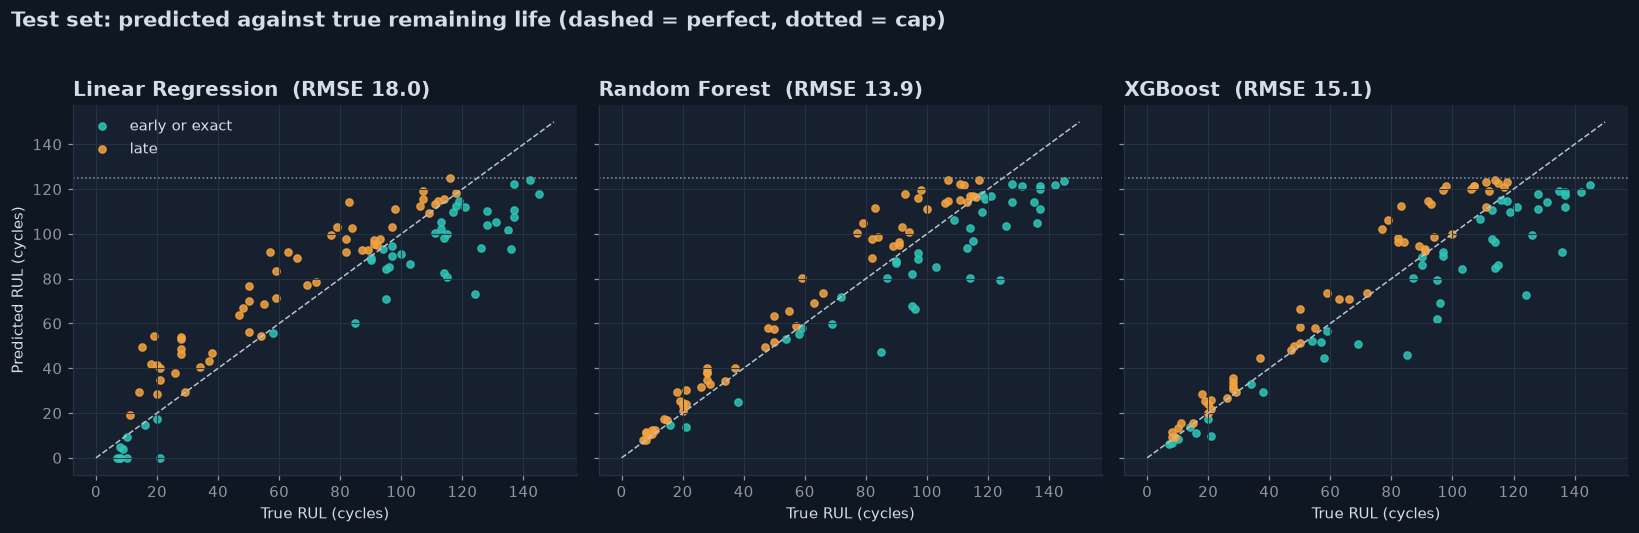

In [6]:
shown_models = ["Linear Regression", "Random Forest", "XGBoost"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), sharex=True, sharey=True)
for ax, name in zip(axes, shown_models):
    predicted = test_predictions[name]
    late = predicted > true_rul
    ax.scatter(true_rul[~late], predicted[~late], color=theme.TEAL, s=22, alpha=0.85, label="early or exact")
    ax.scatter(true_rul[late], predicted[late], color=theme.AMBER, s=22, alpha=0.85, label="late")
    ax.plot([0, 150], [0, 150], color=theme.SILVER, linestyle="--", linewidth=1)
    ax.axhline(config.RUL_CAP, color=theme.MUTED, linestyle=":", linewidth=1)
    ax.set_title(f"{name}  (RMSE {test_results[name]['RMSE']:.1f})")
    ax.set_xlabel("True RUL (cycles)")
axes[0].set_ylabel("Predicted RUL (cycles)")
axes[0].legend(loc="upper left")
fig.suptitle("Test set: predicted against true remaining life (dashed = perfect, dotted = cap)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=theme.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### Where do the errors happen?

An overall score hides *where* a model is good or bad. Here the test engines are grouped by how much life they truly had left.

In [7]:
bands = pd.cut(true_rul, bins=[0, 30, 60, 90, 125, 150], labels=["1-30", "31-60", "61-90", "91-125", "126-145"])
band_rows = {}
for name in shown_models:
    error = test_predictions[name] - true_rul
    grouped = pd.Series(error).groupby(bands, observed=True)
    band_rows[(name, "MAE")] = grouped.apply(lambda e: np.abs(e).mean())
    band_rows[(name, "mean error")] = grouped.mean()
band_table = pd.DataFrame(band_rows)
band_table.insert(0, ("", "engines"), pd.Series(true_rul).groupby(bands, observed=True).size())
band_table.round(1)

Linear Regression            Random Forest            XGBoost  \
        engines               MAE mean error           MAE mean error     MAE   
1-30         25              13.9        8.6           4.6        3.9     3.3   
31-60        14              14.2       13.8           6.5        3.9     6.1   
61-90        15              15.1       11.4          12.9        5.1    14.2   
91-125       35              10.4       -5.8          12.0       -2.0    13.2   
126-145      11              26.5      -26.5          18.5      -18.5    21.7   

                    
        mean error  
1-30           1.5  
31-60          1.6  
61-90          5.1  
91-125        -2.5  
126-145      -21.7

In [8]:
best_name = "XGBoost"
worst = (test_last_rows[["engine_id", "cycle", "true_rul"]]
         .assign(predicted=test_predictions[best_name].astype(float).round(1))
         .assign(error=lambda t: (t["predicted"] - t["true_rul"]).round(1))
         .sort_values("error", key=abs, ascending=False)
         .head(8))
worst.rename(columns={"cycle": "cycles recorded"})

,engine_id,cycles recorded,true_rul,predicted,error
11,12,217,124,72.8,-51.2
88,89,177,136,92.1,-43.9
92,93,244,85,45.9,-39.1
12,13,195,95,61.8,-33.2
14,15,76,83,112.3,29.3
44,45,152,114,84.7,-29.3
29,30,143,115,85.9,-29.1
49,50,74,79,106.2,27.2


**Findings on the test set.**

- **The ranking from cross-validation held.** Tree models first, linear models clearly behind, and all far ahead of predicting the average. Test RMSE for the tree models (13.9 and 15.1) is close to what cross-validation led us to expect (15.2 and 15.4 on the one-point-per-engine check), so the validation procedure was a fair guide.
- **Random Forest scored better than XGBoost on this test set** (RMSE 13.9 against 15.1, NASA score 263 against 322). Cross-validation had them level, and a 1.2-cycle gap on 100 engines is about the size of the fold spread. The fair reading is that they perform similarly, with Random Forest ahead on this particular sample.
- **Tree models are most accurate where it matters most.** For engines with 30 or fewer cycles left, XGBoost is off by about 3 cycles on average and Random Forest by about 5. Linear Regression is off by about 14 in the same band, and its errors there are mostly *late* (mean error +8.6), which is the dangerous direction.
- **All models underestimate engines with more than 125 cycles left**, by about 20 cycles. This is the RUL cap at work: a model trained on labels capped at 125 cannot answer 140. It is a known, accepted consequence of decision D-008, and it is an *early* (cautious) error.
- **The largest XGBoost errors are mostly early predictions on engines with long remaining life**: for example, test engine 12 had 124 cycles left and was predicted to have 73. These engines already show drift but then last longer than the typical training engine did.
- **Late predictions are roughly half of all predictions for every model** (54 to 61 of 100), but large late errors are rare for the tree models: 6 or 7 engines are late by more than 20 cycles, against 15 for the linear models.

**What we cannot claim.** With 100 test engines, small differences between the two tree models are not reliable. None of these models gives any indication of its own uncertainty; a prediction of 73 and a prediction of 3 are both delivered as bare numbers. That is the subject of Phase 8.

## 5. Saving the results

The fitted models go to `models/` (kept out of Git; they can be rebuilt by running this notebook). The result tables go to `experiments/`, which is tracked, so later notebooks compare against exactly these numbers.

In [9]:
models_dir = project_root / "models"
experiments_dir = project_root / "experiments"
models_dir.mkdir(exist_ok=True)
experiments_dir.mkdir(exist_ok=True)

for name in shown_models:
    joblib.dump(fitted_models[name], models_dir / f"fd001_{name.lower().replace(' ', '_')}.joblib")

cv_table.round(4).to_csv(experiments_dir / "fd001_ml_baselines_cv.csv", index_label="model")
test_table_results.round(4).to_csv(experiments_dir / "fd001_ml_baselines_test.csv", index_label="model")
pd.DataFrame({"engine_id": test_last_rows["engine_id"], "true_rul": true_rul,
              **{name: test_predictions[name].round(3) for name in shown_models}}
             ).to_csv(experiments_dir / "fd001_ml_baselines_test_predictions.csv", index=False)

print("Saved models:", sorted(p.name for p in models_dir.glob("fd001_*.joblib")))
print("Saved tables:", sorted(p.name for p in experiments_dir.glob("fd001_ml_baselines*.csv")))

Saved models: ['fd001_linear_regression.joblib', 'fd001_random_forest.joblib', 'fd001_xgboost.joblib']
Saved tables: ['fd001_ml_baselines_cv.csv', 'fd001_ml_baselines_test.csv', 'fd001_ml_baselines_test_predictions.csv']


## 6. Conclusions

| Model | CV RMSE (all rows) | Test RMSE | Test MAE | Test NASA score |
|---|---:|---:|---:|---:|
| Predict the average | 41.7 | 43.1 | 35.9 | 33,629 |
| Linear Regression | 17.1 | 18.0 | 14.3 | 511 |
| Ridge Regression | 16.9 | 17.9 | 14.2 | 497 |
| Random Forest | 13.1 | 13.9 | 10.3 | 263 |
| XGBoost | 13.3 | 15.1 | 10.8 | 322 |

Test figures are measured against the true RUL as given (up to 145), with predictions limited to 0-125.

- The **baseline to beat** in Phase 6 is a test RMSE of about 14 to 15 and a NASA score of about 260 to 320.
- The more complex model did **not** automatically win: Random Forest and XGBoost are level, and the choice between them is about cost. XGBoost trains about seven times faster and is far smaller, which matters for the application later.
- Most of the accuracy comes from the **features** built in Phase 4, not from the choice of tree algorithm.

**Limitations.** Settings were sensible defaults, not tuned (Phase 9). Results are for FD001 only, on simulated data. One training run per model: the tree models depend on a random seed, and the size of that effect has not been measured yet. Published results on this benchmark use a variety of conventions (cap value, whether the test truth is capped), so comparisons with the literature need care and are left to the research-paper phase.

## 7. Next steps

**Notebook 06 - Deep learning.** Train an MLP, LSTM, GRU and a temporal convolutional network on 30-cycle windows, using the same engines, the same cap and the same metrics, and ask honestly whether they improve on about 14 to 15 cycles RMSE.